# Run previous notebook

In [637]:
# %run 01_eda_freight.ipynb

In [638]:
# from IPython.utils.capture import capture_output

# with capture_output():
#     get_ipython().run_line_magic('run', '01_eda_freight.ipynb')

In [639]:
# %pip install phik

In [640]:
# Imports
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
# import phik
# import holidays

# Paths
DATA_DIR = Path("..") / "data"
CHARTS_DIR = Path("..") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

In [641]:
# Rhine Freight Data
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_freight['Date'] = pd.to_datetime(df_freight['Date'], dayfirst=True) 
# Drop empty rows
df_freight = df_freight.dropna(how="all")

# Weather Data
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")
df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True) # dates are dd/mm/yyyy
# Drop empty rows
df_weather = df_weather.dropna(how="all")
df_weather.rename(columns={'date': 'Date'}, inplace=True)

In [642]:
df_complete = pd.merge(df_freight, df_weather, on='Date', how='left')

In [643]:
df_freight.shape, df_weather.shape, df_complete.shape

((1469, 8), (3652, 25), (1469, 32))

In [644]:
df_complete.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avg_uv_index,avgtemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,1.0,2.0,...,0.0,1.0,10.0,122.0,['Overcast'],245.0,WSW,7.0,1.0,14.0
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,1.0,4.0,...,0.0,1.0,0.0,248.0,['Fog'],283.0,WNW,6.0,3.0,12.0
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,1.0,1.0,...,0.0,1.0,10.0,113.0,['Clear'],105.0,ESE,5.0,-2.0,10.0
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,1.0,0.0,...,0.0,1.0,10.0,113.0,['Clear'],210.0,SSW,4.0,0.0,8.0
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,1.0,-1.0,...,0.0,1.0,5.0,143.0,['Mist'],273.0,W,5.0,-3.0,10.0


In [645]:
df_complete.shape

(1469, 32)

In [646]:
df_complete.drop(columns=['avg_uv_index', 'uv_index', "weather_code", "wind_dir"], inplace=True)

In [647]:
df_complete["Kaub_level"] = df_complete["Kaub_level"].interpolate(method="linear", limit_area="inside")

In [648]:
df_complete.dropna(subset=['Freight'], inplace=True)
# Price 5 rows ahead (the last 5 rows get NaN because they have no future)
df_complete['Freight_5days'] = df_complete['Freight'].shift(-5)
# Drop those last 5 rows
df_complete = df_complete.dropna(subset=['Freight_5days']).reset_index(drop=True)


# 1. Baseline Model

In [649]:
col = 'Freight'

# Garante a ordem temporal (se tiveres uma coluna Date)
df_sorted = df_complete.sort_values('Date').reset_index(drop=True)
y = df_sorted[col]

# 1) Maior amplitude em 5 linhas seguidas (como antes)
amplitude = y.rolling(5).max() - y.rolling(5).min()
print('Maior amplitude em 5 linhas:', amplitude.max())

# 2) Previsão = média dos 5 dias anteriores (shift(1) exclui o próprio dia)
pred_mean5 = y.shift(1).rolling(5).mean()
erro_mean5 = (y - pred_mean5).abs()

# 3) Previsão = valor do dia anterior
pred_naive = y.shift(1)
erro_naive = (y - pred_naive).abs()

# Resultados
for nome, erro, pred in [('Média dos 5 dias anteriores', erro_mean5, pred_mean5),
                         ('Valor do dia anterior', erro_naive, pred_naive)]:
    i = erro.idxmax()
    print(f'\n{nome}')
    print('  Erro máximo:', round(erro[i], 2))
    print('  Erro médio (MAE):', round(erro.mean(), 2))
    print('  Valor real:', y[i], '| Previsão:', round(pred[i], 2))
    print('  Linha:', i)

Maior amplitude em 5 linhas: 224.39999999999998

Média dos 5 dias anteriores
  Erro máximo: 177.39
  Erro médio (MAE): 3.89
  Valor real: 151.35 | Previsão: 328.74
  Linha: 1438

Valor do dia anterior
  Erro máximo: 112.35
  Erro médio (MAE): 1.41
  Valor real: 248.1 | Previsão: 360.45
  Linha: 1437


In [650]:
# Previsões (usam só informação até ao dia t)
df_complete['pred_hoje']     = df_complete['Freight']
df_complete['pred_media5']   = df_complete['Freight'].rolling(5).mean()
# Hoje + variação dos últimos 5 dias = 2*y(t) - y(t-5)
df_complete['pred_momentum'] = df_complete['Freight'] + df_complete['Freight'].diff(5)

previsores = {
    'Preço de hoje': 'pred_hoje',
    'Média dos últimos 5 dias': 'pred_media5',
    'Hoje + variação 5 dias': 'pred_momentum',
}

# Mesmas linhas para os três métodos (media5 e momentum geram NaN nas primeiras linhas)
av = df_complete.dropna(subset=list(previsores.values()) + ['Freight_5days'])

def metricas(y_true, y_pred):
    erro = y_true - y_pred
    return {
        'MAE': erro.abs().mean(),
        'RMSE': np.sqrt((erro ** 2).mean()),
        'Erro máx': erro.abs().max(),
    }

# Todos os dias
resultados = pd.DataFrame({
    nome: metricas(av['Freight_5days'], av[col])
    for nome, col in previsores.items()
}).T

print(f'Nº de previsões avaliadas: {len(av)}')
display(resultados.round(2))

# Só dias extremos (top 10% do preço real a 5 dias)
extremo = av['Freight_5days'] >= av['Freight_5days'].quantile(0.90)

resultados_ext = pd.DataFrame({
    nome: metricas(av.loc[extremo, 'Freight_5days'], av.loc[extremo, col])
    for nome, col in previsores.items()
}).T

print('Dias extremos:')
display(resultados_ext.round(2))

Nº de previsões avaliadas: 1444


,MAE,RMSE,Erro máx
Preço de hoje,6.39,15.97,227.7
Média dos últimos 5 dias,8.47,19.44,214.2
Hoje + variação 5 dias,7.46,19.24,247.8


Dias extremos:


,MAE,RMSE,Erro máx
Preço de hoje,22.79,41.97,227.7
Média dos últimos 5 dias,26.96,44.07,214.2
Hoje + variação 5 dias,22.59,42.79,247.8


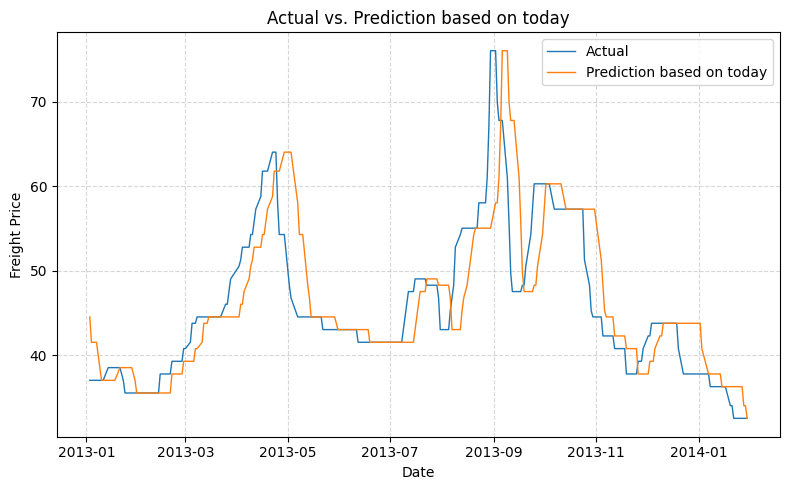

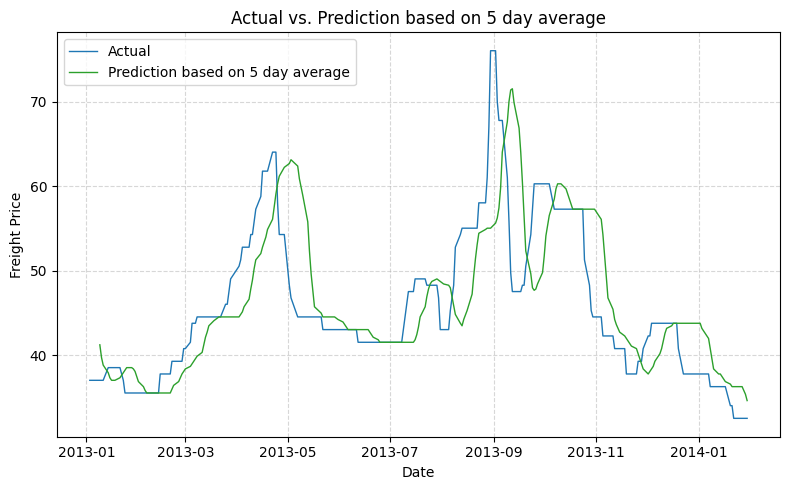

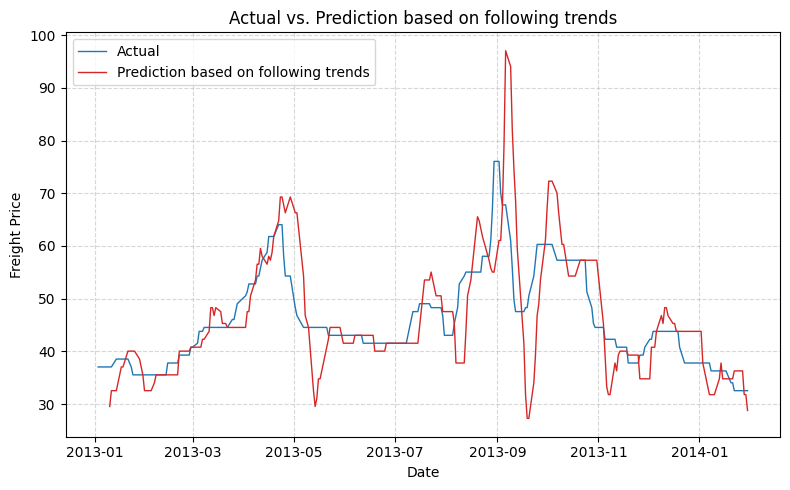

In [651]:
year = int(365 * 5 / 7)
subset = df_complete.iloc[:year]
x = subset['Date']

# Define (column_name, legend_label, line_color) for each baseline
baselines = [
    ('pred_hoje', 'Prediction based on today', '#ff7f0e'),
    ('pred_media5', 'Prediction based on 5 day average', '#2ca02c'),
    ('pred_momentum', 'Prediction based on following trends', '#d62728'),
]

for col, label, color in baselines:
    fig, ax = plt.subplots(figsize=(8, 5))
    
    ax.plot(x, subset['Freight_5days'], label='Actual', color='#1f77b4', linewidth=1)
    ax.plot(x, subset[col], label=label, color=color, linewidth=1)
    
    ax.set(title=f'Actual vs. {label}', xlabel='Date', ylabel='Freight Price')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')
    
    plt.tight_layout()

plt.show()

Cada hipotese de baseline tem vantagens e desvantagens. Pelos resultados a melhor baseline é assumir o preço de hoje para a previsao.
A media dos ultimos 5 dias tende  atrasar o sinal da trend na previsao piorando os resultados. 
A tentativa de seguir a tendencia (Hoje + variação) resulta em menores erros no inicio de tendencias mas erros amplificados quando o crescimento/diminuição de preço muda de sentido.

Por enquanto a baseline escolhida é o preço do proprio dia

# 2. Features

- Que features são mais importantes para o modelo?
- Que features são redundantes?
- Que tipo de split fazer? Cross-validation? Ter a certeza que nao existe data leakage
- Que modelos usar?
- Experimentar PCA para reduzir Weather features e gas price features?

Eliminar features claramente redundantes

In [652]:
df_complete.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1449 non-null   datetime64[ns]
 1   Freight               1449 non-null   float64       
 2   Mogas_Flat            1449 non-null   float64       
 3   Brent_flat            1449 non-null   float64       
 4   Diesel_Flat           1449 non-null   float64       
 5   Heating_Flat          1449 non-null   float64       
 6   Kaub_level            1449 non-null   float64       
 7   freight_ar            714 non-null    float64       
 8   avgtemp               1449 non-null   float64       
 9   cloudcover            1449 non-null   float64       
 10  dewpoint              1449 non-null   float64       
 11  feelslike             1449 non-null   float64       
 12  heatindex             1449 non-null   float64       
 13  humidity          

In [653]:
# corr_above30 = (
#     correlation_matrix['Freight_5days']
#     .loc[lambda s: s > 0.30]            # arbitrary value could be 0.4, 0.5 etc
#     .drop('Freight_5days', errors='ignore')   # remove the target's correlation with itself (1.0)
#     .sort_values(ascending=False)
#     .rename('Correlation')
#     .to_frame()
# )

# corr_above30.round(3)

Encoding features

In [654]:
df_complete.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1449 non-null   datetime64[ns]
 1   Freight               1449 non-null   float64       
 2   Mogas_Flat            1449 non-null   float64       
 3   Brent_flat            1449 non-null   float64       
 4   Diesel_Flat           1449 non-null   float64       
 5   Heating_Flat          1449 non-null   float64       
 6   Kaub_level            1449 non-null   float64       
 7   freight_ar            714 non-null    float64       
 8   avgtemp               1449 non-null   float64       
 9   cloudcover            1449 non-null   float64       
 10  dewpoint              1449 non-null   float64       
 11  feelslike             1449 non-null   float64       
 12  heatindex             1449 non-null   float64       
 13  humidity          

Encoding Date into cos e sin

In [655]:
doy = df_complete['Date'].dt.dayofyear
df_complete['Date_sin'] = np.sin(2 * np.pi * doy / 365.25)
df_complete['Date_cos'] = np.cos(2 * np.pi * doy / 365.25)

In [656]:
df_complete[["Date_sin", "Date_cos"]].head()

,Date_sin,Date_cos
0,0.051584,0.998669
1,0.068755,0.997634
2,0.120126,0.992759
3,0.137185,0.990545
4,0.154204,0.988039


Encoding Weather Description

In [657]:
df_complete["weather_descriptions"] = df_complete["weather_descriptions"].str.strip("[]'")

In [658]:
df_complete = pd.get_dummies(df_complete, columns=['weather_descriptions'], prefix='weather', dtype=int)

In [659]:
df_complete = pd.get_dummies(df_complete, columns=['moon_phase'], prefix='moon', dtype=int)

In [660]:
df_complete.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover',
       'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow',
       'visibility', 'wind_degree', 'wind_speed', 'windchill', 'windgust',
       'Freight_5days', 'pred_hoje', 'pred_media5', 'pred_momentum',
       'Date_sin', 'Date_cos', 'weather_Clear', 'weather_Cloudy',
       'weather_Fog', 'weather_Freezing fog', 'weather_Light rain',
       'weather_Light rain shower', 'weather_Mist',
       'weather_Moderate or heavy rain shower', 'weather_Moderate rain',
       'weather_Overcast', 'weather_Partly cloudy',
       'weather_Patchy light rain with thunder',
       'weather_Patchy rain possible', 'weather_Thundery outbreaks possible',
       'moon_First Quarter', 'moon_Full Moon', 'moon_Last Quarter',
       'moon_New Moon', 'moon_Waning Crescent', 'moo

In [661]:
df_complete.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 54 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Date                                    1449 non-null   datetime64[ns]
 1   Freight                                 1449 non-null   float64       
 2   Mogas_Flat                              1449 non-null   float64       
 3   Brent_flat                              1449 non-null   float64       
 4   Diesel_Flat                             1449 non-null   float64       
 5   Heating_Flat                            1449 non-null   float64       
 6   Kaub_level                              1449 non-null   float64       
 7   freight_ar                              714 non-null    float64       
 8   avgtemp                                 1449 non-null   float64       
 9   cloudcover                              1449 non-nul

## Correlations

In [662]:
import phik
correlation_complete_data = df_complete.copy()

# Garante que é datetime (valores inválidos viram NaT)
correlation_complete_data["Date"] = pd.to_datetime(
    correlation_complete_data["Date"], errors="coerce"
)

# Converte para ordinal, mantendo NaT como NaN
correlation_complete_data["Date"] = correlation_complete_data["Date"].map(
    lambda d: d.toordinal() if pd.notna(d) else np.nan
)

# Calculate Phik matrix (using njobs=1 to prevent Windows crash)
correlation_matrix = correlation_complete_data.phik_matrix(njobs=1)

corr_target = (
    correlation_matrix["Freight_5days"]
    .drop("Freight_5days")                       # remove the self-correlation (always 1)
    .sort_values(key=abs, ascending=False)       # strongest first, ignoring sign
    .to_frame("corr_with_Freight_5days")
)
print(corr_target.round(3))



interval columns not set, guessing: ['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat', 'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover', 'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp', 'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow', 'visibility', 'wind_degree', 'wind_speed', 'windchill', 'windgust', 'Freight_5days', 'pred_hoje', 'pred_media5', 'pred_momentum', 'Date_sin', 'Date_cos', 'weather_Clear', 'weather_Cloudy', 'weather_Fog', 'weather_Freezing fog', 'weather_Light rain', 'weather_Light rain shower', 'weather_Mist', 'weather_Moderate or heavy rain shower', 'weather_Moderate rain', 'weather_Overcast', 'weather_Partly cloudy', 'weather_Patchy light rain with thunder', 'weather_Patchy rain possible', 'weather_Thundery outbreaks possible', 'moon_First Quarter', 'moon_Full Moon', 'moon_Last Quarter', 'moon_New Moon', 'moon_Waning Crescent', 'moon_Waning Gibbous', 'moon_Waxing Crescent', 'moon_Waxing Gibbous']
  

## Train Test split


In [663]:
from sklearn.model_selection import TimeSeriesSplit

df_model = df_complete.copy()  # Create a copy of df_complete to avoid modifying the original DataFrame

df_model["Kaub_level"] = df_model["Kaub_level"].interpolate(method="linear", limit_area="inside")
df_model['freight_ar'] = df_model['freight_ar'].fillna(0)


target = "Freight_5days"
baselines = ["pred_hoje", "pred_media5", "pred_momentum"]   # keep for comparison, not as features
drop_cols = ["Date", target] + baselines

X = df_model.drop(columns=drop_cols, errors="ignore")
y = df_model[target]
dates = df_model["Date"]

# gap=5: the last 5 training rows have targets that fall inside the test period -> leave them out
tscv = TimeSeriesSplit(n_splits=5, gap=5)

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    print(f"Fold {fold}: train {dates.iloc[train_idx[0]].date()} -> {dates.iloc[train_idx[-1]].date()} ({len(train_idx)} rows) | "
          f"test {dates.iloc[test_idx[0]].date()} -> {dates.iloc[test_idx[-1]].date()} ({len(test_idx)} rows)")

Fold 0: train 2013-01-03 -> 2013-12-23 (239 rows) | test 2014-01-08 -> 2015-01-05 (241 rows)
Fold 1: train 2013-01-03 -> 2014-12-22 (480 rows) | test 2015-01-07 -> 2015-12-30 (241 rows)
Fold 2: train 2013-01-03 -> 2015-12-18 (721 rows) | test 2016-01-04 -> 2016-12-23 (241 rows)
Fold 3: train 2013-01-03 -> 2016-12-16 (962 rows) | test 2016-12-28 -> 2017-12-22 (241 rows)
Fold 4: train 2013-01-03 -> 2017-12-15 (1203 rows) | test 2017-12-27 -> 2018-12-18 (241 rows)


## Lasso Linear Regression

In [664]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, max_error

def train_Lasso_on_TSCV(df_model, tscv, X):

    def metrics(y_true, y_pred):
        return {
            "MAE":  mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MaxErr": max_error(y_true, y_pred),
        }

    alphas = np.logspace(-3, 2, 60)
    cv_scores = {a: [] for a in alphas}                 # alpha -> list of metric dicts (one per fold)
    base_scores = {b: [] for b in baselines}

    for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
        scaler = StandardScaler().fit(X.iloc[train_idx])
        Xtr = scaler.transform(X.iloc[train_idx])
        Xva = scaler.transform(X.iloc[val_idx])
        ytr, yva = y.iloc[train_idx], y.iloc[val_idx]

        for a in alphas:
            m = Lasso(alpha=a, max_iter=50000).fit(Xtr, ytr)
            cv_scores[a].append(metrics(yva, m.predict(Xva)))

        for b in baselines:
            base_scores[b].append(metrics(yva, df_model[b].iloc[val_idx]))

    # Choose alpha by mean RMSE across folds
    mean_rmse = pd.Series({a: np.mean([f["RMSE"] for f in folds]) for a, folds in cv_scores.items()})
    best_alpha = mean_rmse.idxmin()
    print(f"best alpha: {best_alpha:.4f}\n")

    # Per-fold table for the best alpha
    lasso_folds = pd.DataFrame(cv_scores[best_alpha])
    lasso_folds.index.name = "fold"
    print("Lasso per fold:")
    print(lasso_folds.round(3))
    print("\nLasso mean across folds:")
    print(lasso_folds.mean().round(3))

    # Baselines, same metrics
    print("\nBaselines (mean across folds):")
    print(pd.DataFrame({b: pd.DataFrame(s).mean() for b, s in base_scores.items()}).T.round(3))


    return best_alpha

In [665]:
print(f'Train with every feature')
best_alpha = train_Lasso_on_TSCV(df_model, tscv, X) #Train with every feature

Train with every feature
best alpha: 0.3486

Lasso per fold:
         MAE    RMSE   MaxErr
fold                         
0      3.615   4.381   11.807
1     13.023  20.135   67.865
2      7.563  10.102   30.873
3      7.623  11.798   67.237
4     15.310  31.227  201.058

Lasso mean across folds:
MAE        9.427
RMSE      15.529
MaxErr    75.768
dtype: float64

Baselines (mean across folds):
                 MAE    RMSE  MaxErr
pred_hoje      6.974  14.460   86.79
pred_media5    9.260  17.838   86.91
pred_momentum  7.974  16.544   91.86


In [666]:
X1_keep_cols = ['Freight', 'freight_ar', 'Kaub_level', 'Brent_flat', 'Date_sin', 'Date_cos', 'Diesel_Flat', 'humidity', 'avgtemp']
print(f'Train with features: {X1_keep_cols}')
X1 = X[X1_keep_cols]
tscv_max = TimeSeriesSplit(n_splits=5, gap=5, max_train_size=500)
train_Lasso_on_TSCV(df_model, tscv_max, X1)

Train with features: ['Freight', 'freight_ar', 'Kaub_level', 'Brent_flat', 'Date_sin', 'Date_cos', 'Diesel_Flat', 'humidity', 'avgtemp']
best alpha: 0.2868

Lasso per fold:
         MAE    RMSE   MaxErr
fold                         
0      3.575   4.364   11.461
1     13.009  20.033   67.228
2      9.263  11.556   32.984
3      9.373  12.881   64.536
4     19.128  33.320  179.363

Lasso mean across folds:
MAE       10.870
RMSE      16.431
MaxErr    71.115
dtype: float64

Baselines (mean across folds):
                 MAE    RMSE  MaxErr
pred_hoje      6.974  14.460   86.79
pred_media5    9.260  17.838   86.91
pred_momentum  7.974  16.544   91.86


np.float64(0.2868316813342009)

Lasso regression has "built-in" feature engineering so there is no difference in selecting most relevant features and less relevant features, since the Lasso regression will set redundant coefficients closer to zero.

Comparing Lasso with baselines max error for Lasso was lower while the MAE and RMSE were similar (or even slightly worse)

In [667]:
splitters = {
    "expanding (default)": TimeSeriesSplit(n_splits=5, gap=5),                        # train on all past data
    "rolling (500)":       TimeSeriesSplit(n_splits=5, gap=5, max_train_size=500),    # train on the last 500 rows only
}

In [668]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, max_error

models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=best_alpha, max_iter=50000)),
}

def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MaxErr": max_error(y_true, y_pred)}

results, preds = [], []
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        bench = df_model["pred_hoje"].iloc[test_idx]

        results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)",
                        **metrics(y_test, bench)})

        for name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            row = {"scheme": scheme, "fold": fold, "model": name, **metrics(y_test, y_pred)}
            if name == "Lasso":
                row["n_features"] = int((model[-1].coef_ != 0).sum())   # sparsity per fold
            results.append(row)
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": name,
                                       "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": y_pred,
                                       "benchmark": bench.values}))

res = pd.DataFrame(results)
preds = pd.concat(preds, ignore_index=True)

# Tables
print(res.pivot(index=["scheme", "fold"], columns="model", values="MAE").round(2))
print(res.groupby(["scheme", "model"])[["MAE", "RMSE", "MaxErr"]].mean().round(2))

model                     Benchmark (today)  Lasso  Ridge
scheme              fold                                 
expanding (default) 0                  2.27   3.62   9.21
                    1                  8.02  13.02  14.49
                    2                  5.43   7.56   9.62
                    3                  6.50   7.62   8.05
                    4                 12.65  15.31  18.39
rolling (500)       0                  2.27   3.62   9.21
                    1                  8.02  13.02  14.49
                    2                  5.43   9.74  11.51
                    3                  6.50   9.22  11.60
                    4                 12.65  19.37  22.84
                                         MAE   RMSE  MaxErr
scheme              model                                  
expanding (default) Benchmark (today)   6.97  14.46   86.79
                    Lasso               9.43  15.53   75.77
                    Ridge              11.95  17.74   76.95
roll

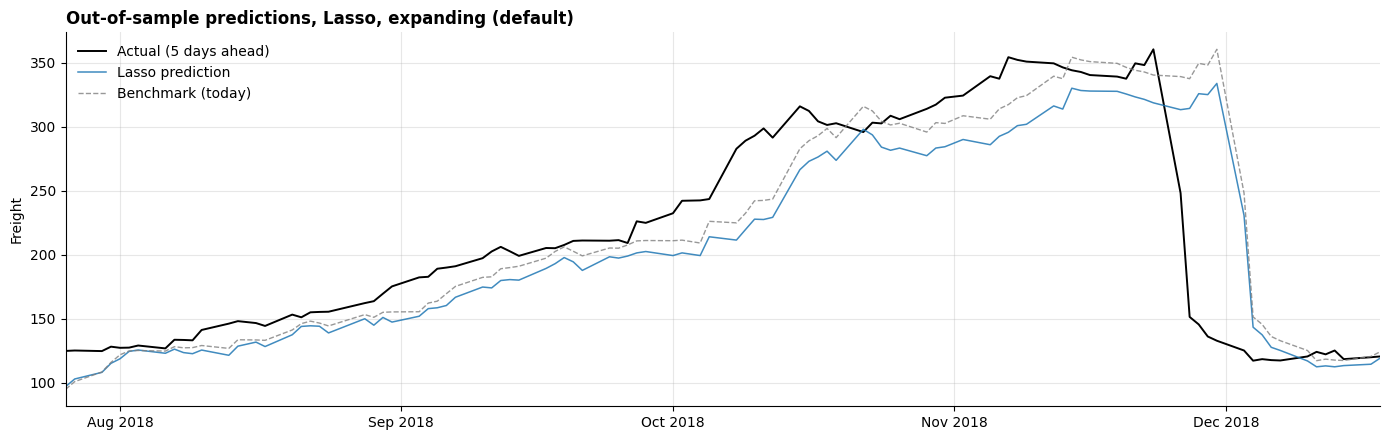

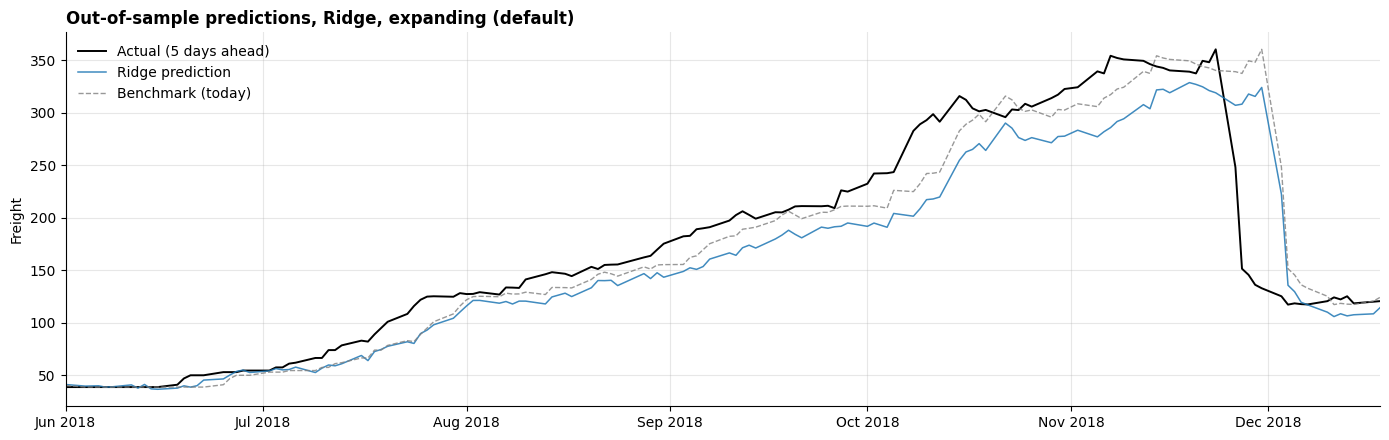

In [682]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

def plot_model(preds, model_name, scheme="expanding (default)", last_n=None, start=None, end=None):
    p = preds[(preds["scheme"] == scheme) & (preds["model"] == model_name)].sort_values("Date")

    # zoom window
    if start is not None: p = p[p["Date"] >= pd.Timestamp(start)]
    if end   is not None: p = p[p["Date"] <= pd.Timestamp(end)]
    if last_n is not None: p = p.tail(last_n)

    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(p["Date"], p["actual"], color="black", lw=1.4, label="Actual (5 days ahead)")
    ax.plot(p["Date"], p["pred"], color="tab:blue", lw=1.1, alpha=0.85, label=f"{model_name} prediction")
    ax.plot(p["Date"], p["benchmark"], color="tab:grey", lw=1, ls="--", alpha=0.8, label="Benchmark (today)")

    # fold starts, only if they fall inside the window
    lo, hi = p["Date"].min(), p["Date"].max()
    for f, g in preds[(preds["scheme"] == scheme) & (preds["model"] == model_name)].groupby("fold"):
        d0 = g["Date"].min()
        if lo <= d0 <= hi:
            ax.axvline(d0, color="grey", lw=0.6, ls=":")

    ax.set_xlim(lo, hi)
    span = (hi - lo).days
    if span > 700:
        ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    else:
        ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

    ax.set_ylabel("Freight"); ax.legend(frameon=False, loc="upper left")
    ax.set_title(f"Out-of-sample predictions, {model_name}, {scheme}", loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

plot_model(preds, "Lasso", last_n=100)
plot_model(preds, "Ridge", start="2018-06-01", end="2018-12-31")

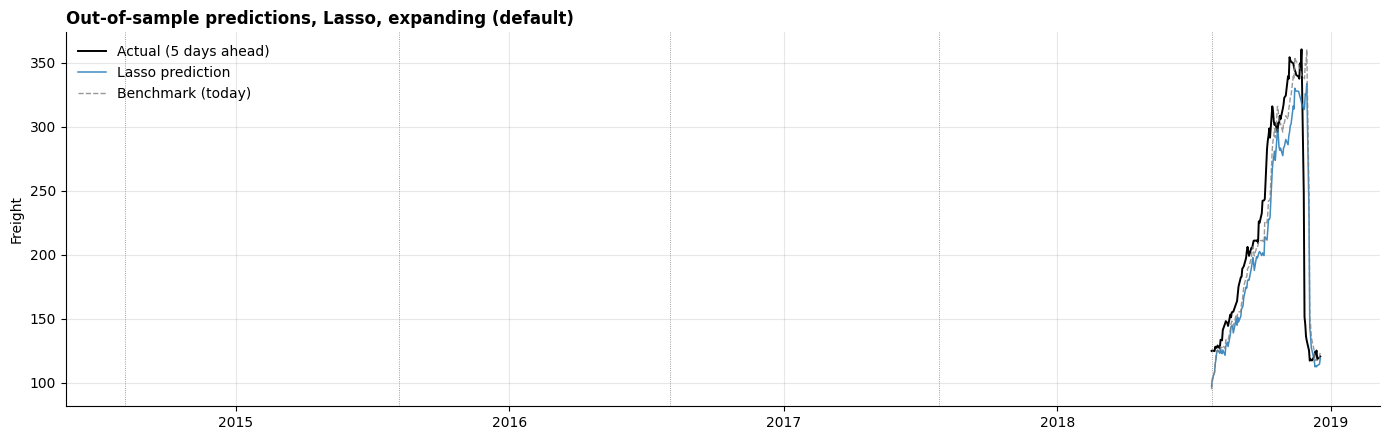

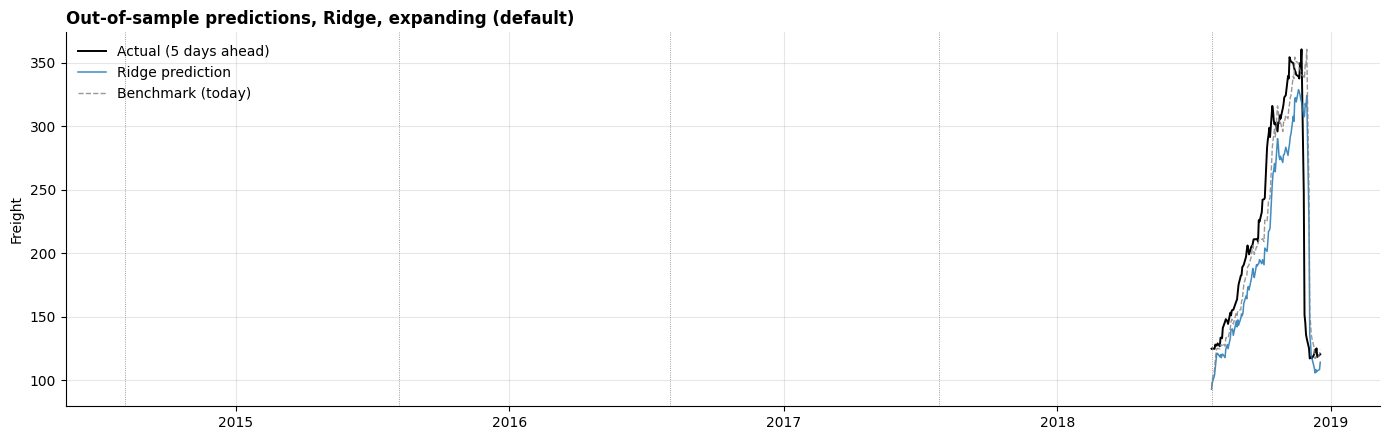

In [681]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_model(preds, model_name, scheme="expanding (default)"):
    p = preds[(preds["scheme"] == scheme) & (preds["model"] == model_name)]
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(p["Date"].tail(100), p["actual"].tail(100), color="black", lw=1.4, label="Actual (5 days ahead)")
    ax.plot(p["Date"].tail(100), p["pred"].tail(100), color="tab:blue", lw=1.1, alpha=0.85, label=f"{model_name} prediction")
    ax.plot(p["Date"].tail(100), p["benchmark"].tail(100), color="tab:grey", lw=1, ls="--", alpha=0.8, label="Benchmark (today)")
    for f, g in p.groupby("fold"):
        ax.axvline(g["Date"].tail(100).min(), color="grey", lw=0.6, ls=":")
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_ylabel("Freight"); ax.legend(frameon=False, loc="upper left")
    ax.set_title(f"Out-of-sample predictions, {model_name}, {scheme}", loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

plot_model(preds, "Lasso")
plot_model(preds, 'Ridge')

## XGBoost

In [ ]:
def add_features(X):

    keep = ['Freight', 'freight_ar', 'Kaub_level', 'Brent_flat', 'Date_sin', 'Date_cos']
    X = X.copy()
    X1 = X[keep]
    f = X1["Freight"]
    for k in [1, 2, 5, 10, 20]:
        X1[f"Freight_d{k}"] = f.diff(k)                  # past changes (momentum)
    X1["Freight_ret5"]  = f.pct_change(5)
    X1["Freight_vs_ma10"] = f - f.rolling(10).mean()      # distance from recent average (mean reversion)
    X1["Freight_vs_ma30"] = f - f.rolling(30).mean()
    X1["Freight_vol10"] = f.diff().rolling(10).std()      # recent volatility
    X1["Freight_vs_max60"] = f - f.rolling(60).max()      # position within recent range

    return X


In [693]:
def add_features_updated(X):

    keep = ['Freight', 'freight_ar']
    X = X.copy()
    X1 = X[keep]
    f = X1["Freight"]
    for k in [1, 2, 5]:
        X1[f"Freight_d{k}"] = f.diff(k)                  # past changes (momentum)

    return X1

In [671]:
X = add_features(X)

C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_15596\2452410525.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X1[f"Freight_d{k}"] = f.diff(k)                  # past changes (momentum)
C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_15596\2452410525.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X1[f"Freight_d{k}"] = f.diff(k)                  # past changes (momentum)
C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_15596\2452410525.py:8: SettingWithCopyWarning: 
A value is trying to be set o

In [672]:
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

param_dist = {
    "n_estimators":  [100, 200, 300, 400],
    "max_depth":     randint(2, 7),
    "learning_rate": loguniform(0.01, 0.1),
}

def run_xgb(X, y, df_model, dates, splitters, n_iter=25, predict_delta=True,
            base_col="Freight", label="XGBoost"):
    """predict_delta=True: the model predicts (price in 5 days - price today)
    and today's price is added back to get the forecast."""
    results, preds, best_params = [], [], []

    for scheme, tscv in splitters.items():
        for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            # offset: today's price (or 0 for the level target)
            off_train = X_train[base_col] if predict_delta else 0
            off_test  = X_test[base_col]  if predict_delta else 0
            y_fit = y_train - off_train                      # target the model learns

            # inner search: only uses this fold's training data
            inner_cv = TimeSeriesSplit(n_splits=3, gap=5)
            search = RandomizedSearchCV(
                XGBRegressor(objective="reg:squarederror", tree_method="hist", random_state=42, n_jobs=1),
                param_distributions=param_dist, n_iter=n_iter, cv=inner_cv,
                scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1, refit=True,
            )
            search.fit(X_train, y_fit)
            y_pred = search.predict(X_test) + off_test       # add today's price back

            results.append({"scheme": scheme, "fold": fold, "model": label,
                            **metrics(y_test, y_pred)})
            best_params.append({"scheme": scheme, "fold": fold, **search.best_params_})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": label,
                                       "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": np.asarray(y_pred),
                                       "benchmark": df_model["pred_hoje"].iloc[test_idx].values}))
            print(f"{scheme} | fold {fold} done | RMSE {results[-1]['RMSE']:.2f}")

    return pd.DataFrame(results), pd.concat(preds, ignore_index=True), pd.DataFrame(best_params)

# Delta version (predicts the 5-day change)
res_xgb_d, preds_xgb_d, params_xgb_d = run_xgb(
    X, y, df_model, dates, splitters, n_iter=25, predict_delta=True, label="XGBoost (delta)")

expanding (default) | fold 0 done | RMSE 3.27
expanding (default) | fold 1 done | RMSE 16.82
expanding (default) | fold 2 done | RMSE 9.42
expanding (default) | fold 3 done | RMSE 10.73
expanding (default) | fold 4 done | RMSE 31.99
rolling (500) | fold 0 done | RMSE 3.27
rolling (500) | fold 1 done | RMSE 16.82
rolling (500) | fold 2 done | RMSE 9.43
rolling (500) | fold 3 done | RMSE 11.23
rolling (500) | fold 4 done | RMSE 31.01


In [673]:
res_xgb_l, preds_xgb_l, params_xgb_l = run_xgb(
    X, y, df_model, dates, splitters, n_iter=25, predict_delta=False, label="XGBoost (level)")

res_all = pd.concat([res, res_xgb_l, res_xgb_d], ignore_index=True)
print(res_all.groupby(["scheme", "model"])[["MAE", "RMSE", "MaxErr"]].mean().round(2))

expanding (default) | fold 0 done | RMSE 5.73
expanding (default) | fold 1 done | RMSE 57.54
expanding (default) | fold 2 done | RMSE 14.25
expanding (default) | fold 3 done | RMSE 13.98
expanding (default) | fold 4 done | RMSE 59.35
rolling (500) | fold 0 done | RMSE 5.73
rolling (500) | fold 1 done | RMSE 57.54
rolling (500) | fold 2 done | RMSE 12.72
rolling (500) | fold 3 done | RMSE 14.78
rolling (500) | fold 4 done | RMSE 102.95
                                         MAE   RMSE  MaxErr
scheme              model                                  
expanding (default) Benchmark (today)   6.97  14.46   86.79
                    Lasso               9.43  15.53   75.77
                    Ridge              11.95  17.74   76.95
                    XGBoost (delta)     8.09  14.45   74.56
                    XGBoost (level)    17.19  30.17  101.12
rolling (500)       Benchmark (today)   6.97  14.46   86.79
                    Lasso              10.99  16.55   70.57
                    R

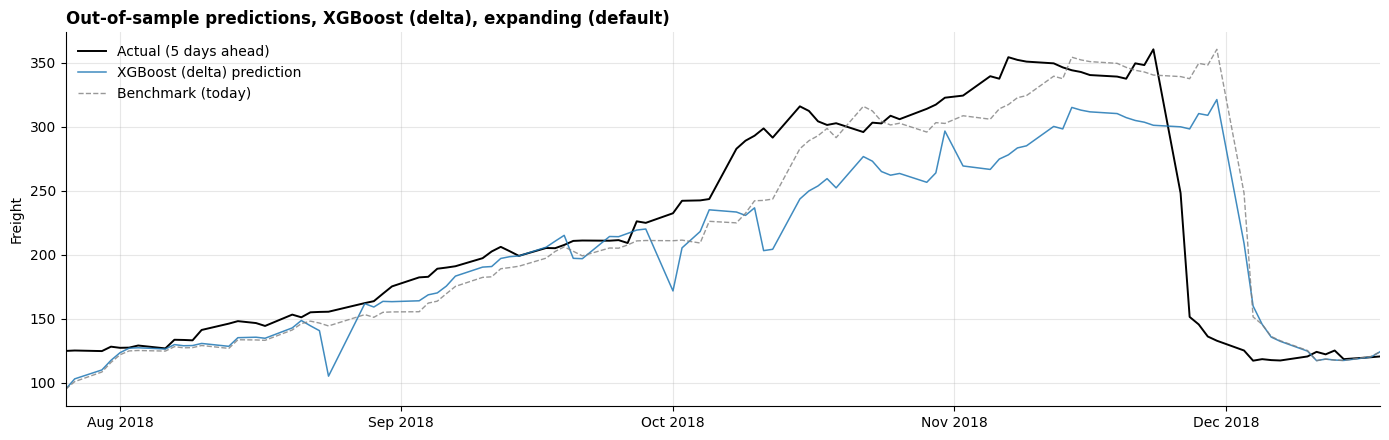

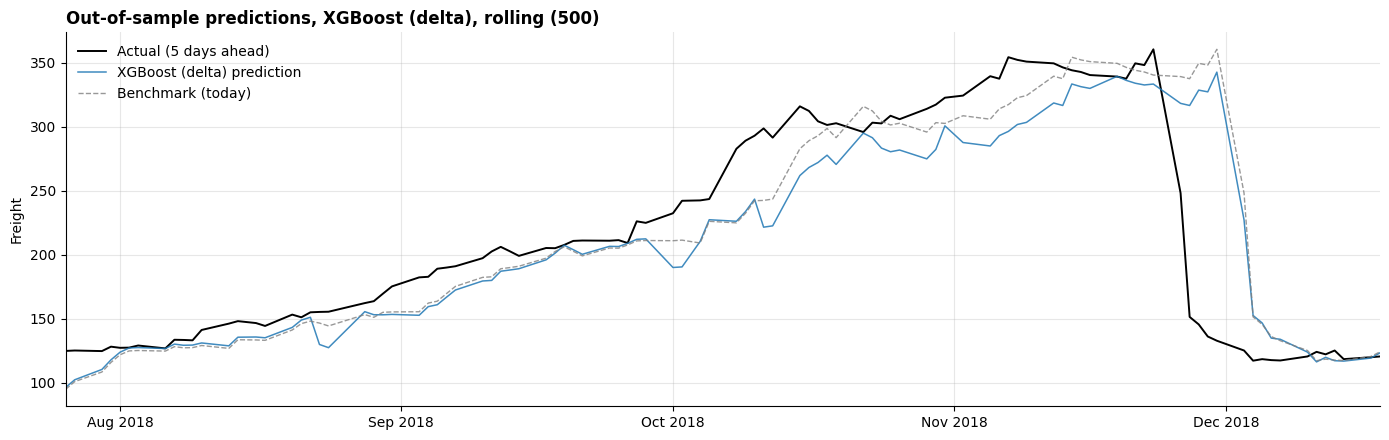

In [685]:
preds_all = pd.concat([preds, preds_xgb_l, preds_xgb_d], ignore_index=True)
for scheme in splitters:
    plot_model(preds_all, "XGBoost (delta)", scheme=scheme, last_n=100)

In [675]:
summary = (res_all.groupby(["scheme", "model"])
           .agg(MAE=("MAE", "mean"),
                RMSE=("RMSE", "mean"),
                MaxErr=("MaxErr", "max"))
           .round(2))
print(summary)

                                         MAE   RMSE  MaxErr
scheme              model                                  
expanding (default) Benchmark (today)   6.97  14.46  227.70
                    Lasso               9.43  15.53  201.06
                    Ridge              11.95  17.74  191.37
                    XGBoost (delta)     8.09  14.45  188.45
                    XGBoost (level)    17.19  30.17  207.81
rolling (500)       Benchmark (today)   6.97  14.46  227.70
                    Lasso              10.99  16.55  176.52
                    Ridge              13.93  19.31  176.16
                    XGBoost (delta)     8.12  14.35  209.88
                    XGBoost (level)    23.90  38.74  274.99


Updated features based on shap

In [694]:
X = add_features_updated(X)

C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_15596\2467922802.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X1[f"Freight_d{k}"] = f.diff(k)                  # past changes (momentum)
C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_15596\2467922802.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X1[f"Freight_d{k}"] = f.diff(k)                  # past changes (momentum)
C:\Users\PedroJorge\AppData\Local\Temp\ipykernel_15596\2467922802.py:8: SettingWithCopyWarning: 
A value is trying to be set o

In [695]:
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

param_dist = {
    "n_estimators":  [100, 200, 300, 400],
    "max_depth":     randint(2, 7),
    "learning_rate": loguniform(0.01, 0.1),
}

def run_xgb(X, y, df_model, dates, splitters, n_iter=25, predict_delta=True,
            base_col="Freight", label="XGBoost"):
    """predict_delta=True: the model predicts (price in 5 days - price today)
    and today's price is added back to get the forecast."""
    results, preds, best_params = [], [], []

    for scheme, tscv in splitters.items():
        for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            # offset: today's price (or 0 for the level target)
            off_train = X_train[base_col] if predict_delta else 0
            off_test  = X_test[base_col]  if predict_delta else 0
            y_fit = y_train - off_train                      # target the model learns

            # inner search: only uses this fold's training data
            inner_cv = TimeSeriesSplit(n_splits=3, gap=5)
            search = RandomizedSearchCV(
                XGBRegressor(objective="reg:squarederror", tree_method="hist", random_state=42, n_jobs=1),
                param_distributions=param_dist, n_iter=n_iter, cv=inner_cv,
                scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1, refit=True,
            )
            search.fit(X_train, y_fit)
            y_pred = search.predict(X_test) + off_test       # add today's price back

            results.append({"scheme": scheme, "fold": fold, "model": label,
                            **metrics(y_test, y_pred)})
            best_params.append({"scheme": scheme, "fold": fold, **search.best_params_})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": label,
                                       "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": np.asarray(y_pred),
                                       "benchmark": df_model["pred_hoje"].iloc[test_idx].values}))
            print(f"{scheme} | fold {fold} done | RMSE {results[-1]['RMSE']:.2f}")

    return pd.DataFrame(results), pd.concat(preds, ignore_index=True), pd.DataFrame(best_params)

# Delta version (predicts the 5-day change)
res_xgb_d, preds_xgb_d, params_xgb_d = run_xgb(
    X, y, df_model, dates, splitters, n_iter=25, predict_delta=True, label="XGBoost (delta)")

expanding (default) | fold 0 done | RMSE 3.09
expanding (default) | fold 1 done | RMSE 16.99
expanding (default) | fold 2 done | RMSE 8.94
expanding (default) | fold 3 done | RMSE 10.25
expanding (default) | fold 4 done | RMSE 30.83
rolling (500) | fold 0 done | RMSE 3.09
rolling (500) | fold 1 done | RMSE 16.99
rolling (500) | fold 2 done | RMSE 8.85
rolling (500) | fold 3 done | RMSE 11.49
rolling (500) | fold 4 done | RMSE 32.54


In [696]:
res_xgb_l, preds_xgb_l, params_xgb_l = run_xgb(
    X, y, df_model, dates, splitters, n_iter=25, predict_delta=False, label="XGBoost (level)")

res_all = pd.concat([res, res_xgb_l, res_xgb_d], ignore_index=True)
print(res_all.groupby(["scheme", "model"])[["MAE", "RMSE", "MaxErr"]].mean().round(2))

expanding (default) | fold 0 done | RMSE 4.05
expanding (default) | fold 1 done | RMSE 53.87
expanding (default) | fold 2 done | RMSE 8.88
expanding (default) | fold 3 done | RMSE 15.32
expanding (default) | fold 4 done | RMSE 62.14
rolling (500) | fold 0 done | RMSE 4.05
rolling (500) | fold 1 done | RMSE 53.87
rolling (500) | fold 2 done | RMSE 9.26
rolling (500) | fold 3 done | RMSE 15.76
rolling (500) | fold 4 done | RMSE 92.14
                                         MAE   RMSE  MaxErr
scheme              model                                  
expanding (default) Benchmark (today)   6.97  14.46   86.79
                    Lasso               9.43  15.53   75.77
                    Ridge              11.95  17.74   76.95
                    XGBoost (delta)     7.48  14.02   79.56
                    XGBoost (level)    16.33  28.85  103.88
rolling (500)       Benchmark (today)   6.97  14.46   86.79
                    Lasso              10.99  16.55   70.57
                    Ridg

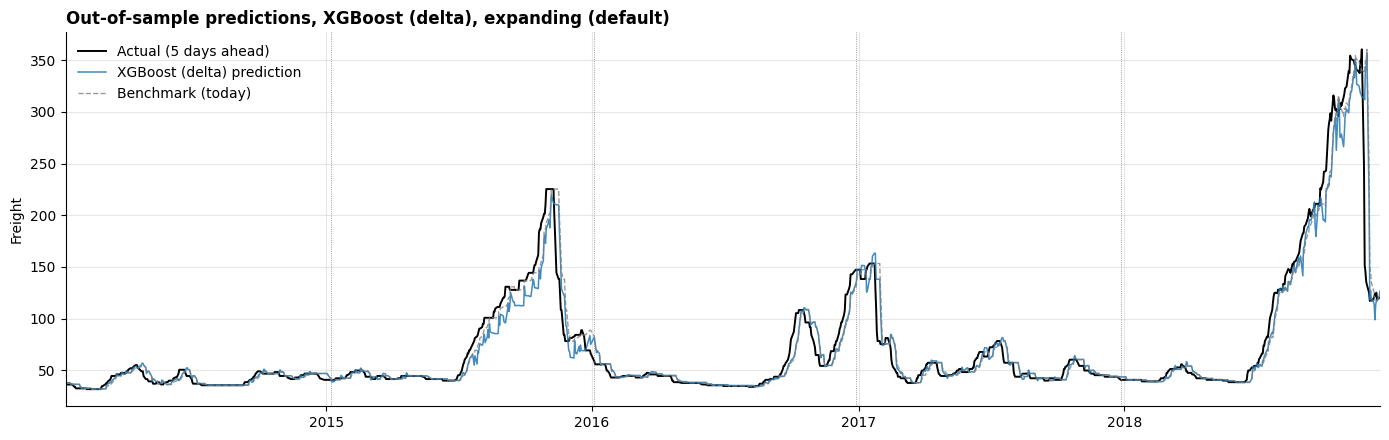

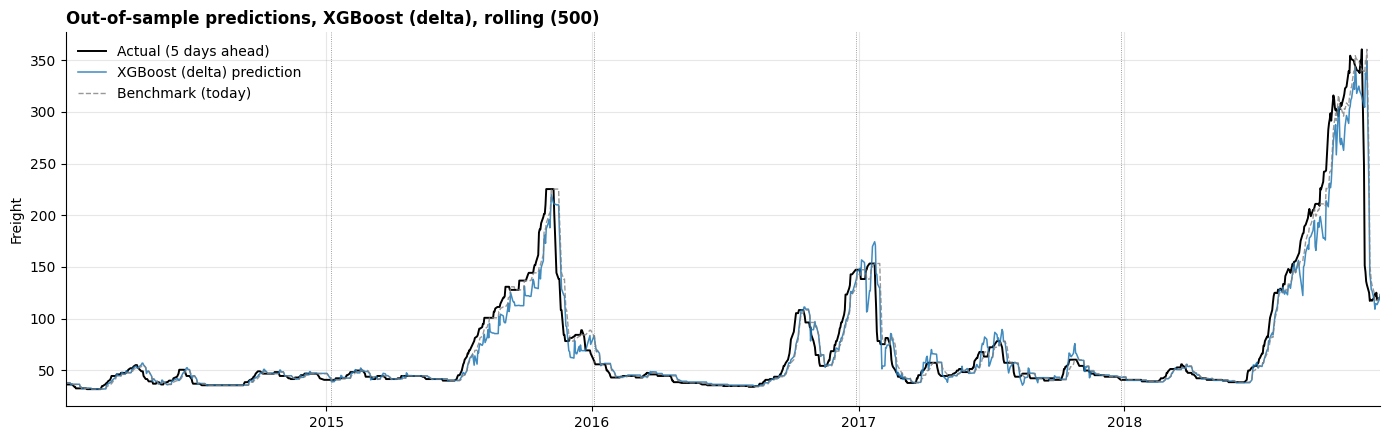

In [702]:
preds_all = pd.concat([preds, preds_xgb_l, preds_xgb_d], ignore_index=True)
for scheme in splitters:
    plot_model(preds_all, "XGBoost (delta)", scheme=scheme)

In [700]:
summary = (res_all.groupby(["scheme", "model"])
           .agg(MAE=("MAE", "mean"),
                RMSE=("RMSE", "mean"),
                MaxErr=("MaxErr", "max"))
           .round(2))
print(summary)

                                         MAE   RMSE  MaxErr
scheme              model                                  
expanding (default) Benchmark (today)   6.97  14.46  227.70
                    Lasso               9.43  15.53  201.06
                    Ridge              11.95  17.74  191.37
                    XGBoost (delta)     7.48  14.02  224.27
                    XGBoost (level)    16.33  28.85  208.40
rolling (500)       Benchmark (today)   6.97  14.46  227.70
                    Lasso              10.99  16.55  176.52
                    Ridge              13.93  19.31  176.16
                    XGBoost (delta)     8.32  14.59  216.61
                    XGBoost (level)    20.25  35.02  248.31


In [676]:
# Per fold
print(res_xgb.pivot(index=["scheme", "fold"], columns="model", values="MAE").round(2))

# Mean per scheme
print(res_xgb.groupby(["scheme", "model"])[["MAE", "RMSE", "MaxErr"]].mean().round(2))

# Chosen hyperparameters per fold (check how stable they are)
print(params_xgb.round(4))

# Combined with the benchmark, Ridge and Lasso from before
res_all = pd.concat([res, res_xgb], ignore_index=True)
preds_all = pd.concat([preds, preds_xgb], ignore_index=True)
print(res_all.groupby(["scheme", "model"])[["MAE", "RMSE", "MaxErr"]].mean().round(2))

model                     XGBoost
scheme              fold         
expanding (default) 0        4.72
                    1       35.83
                    2        8.45
                    3        8.54
                    4       28.42
rolling (500)       0        4.72
                    1       35.83
                    2        7.72
                    3        9.83
                    4       58.65
                               MAE   RMSE  MaxErr
scheme              model                        
expanding (default) XGBoost  17.19  30.25   99.22
rolling (500)       XGBoost  23.35  38.38  115.16
                scheme  fold  learning_rate  max_depth  n_estimators
0  expanding (default)     0         0.0102          2           148
1  expanding (default)     1         0.0102          2           148
2  expanding (default)     2         0.0160          4           314
3  expanding (default)     3         0.0102          2           148
4  expanding (default)     4         0.0467    

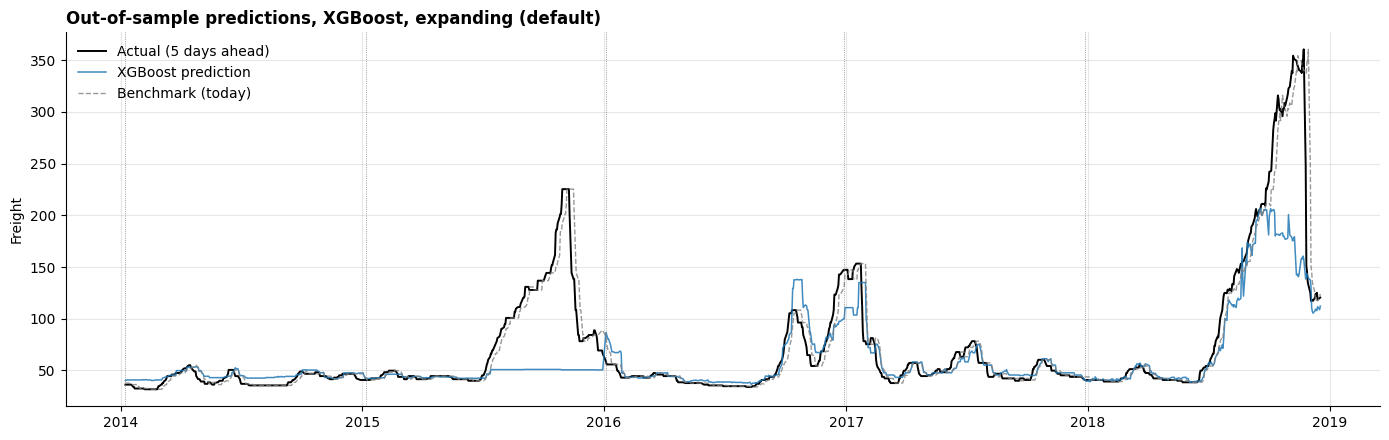

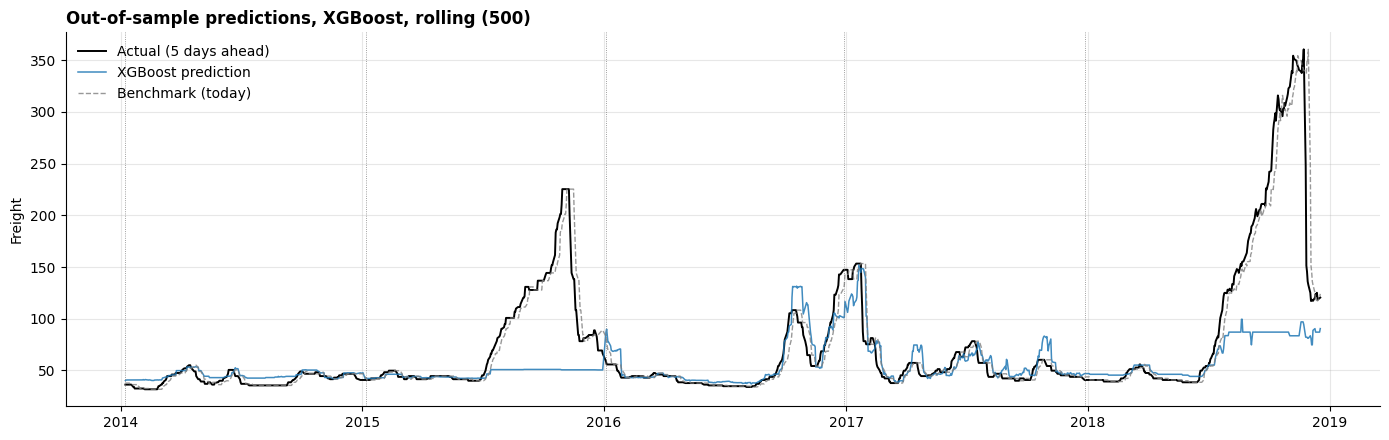

In [677]:
for scheme in splitters:
    plot_model(preds_all, "XGBoost", scheme=scheme)

In [678]:
summary = (res_all.groupby(["scheme", "model"])
           .agg(MAE=("MAE", "mean"),
                RMSE=("RMSE", "mean"),
                MaxErr=("MaxErr", "max"))
           .round(2))
print(summary)

                                         MAE   RMSE  MaxErr
scheme              model                                  
expanding (default) Benchmark (today)   6.97  14.46  227.70
                    Lasso               9.43  15.53  201.06
                    Ridge              11.95  17.74  191.37
                    XGBoost            17.19  30.25  207.01
rolling (500)       Benchmark (today)   6.97  14.46  227.70
                    Lasso              10.99  16.55  176.52
                    Ridge              13.93  19.31  176.16
                    XGBoost            23.35  38.38  270.78


### SHAP

Index(['Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat', 'Heating_Flat',
       'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover', 'dewpoint',
       'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow',
       'visibility', 'wind_degree', 'wind_speed', 'windchill', 'windgust',
       'Date_sin', 'Date_cos', 'weather_Clear', 'weather_Cloudy',
       'weather_Fog', 'weather_Freezing fog', 'weather_Light rain',
       'weather_Light rain shower', 'weather_Mist',
       'weather_Moderate or heavy rain shower', 'weather_Moderate rain',
       'weather_Overcast', 'weather_Partly cloudy',
       'weather_Patchy light rain with thunder',
       'weather_Patchy rain possible', 'weather_Thundery outbreaks possible',
       'moon_First Quarter', 'moon_Full Moon', 'moon_Last Quarter',
       'moon_New Moon', 'moon_Waning Crescent', 'moon_Waning Gibbous',
       'moon_Waxing Crescent', 'moon_Waxing Gibbous', 'Fre

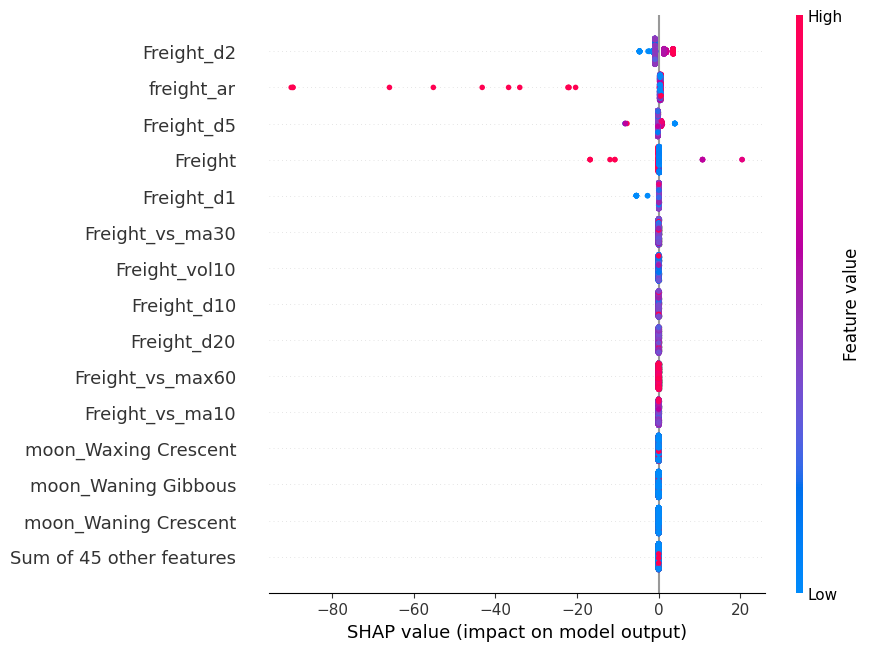

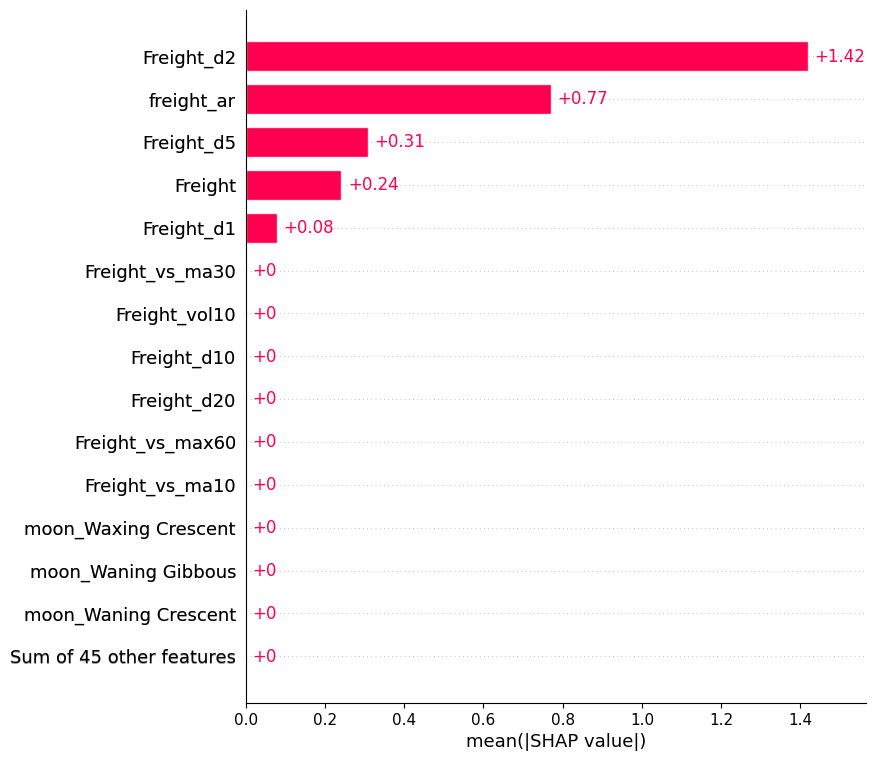

In [692]:
# pip install shap
import shap
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

# 1) Hyperparameters from the last expanding fold (the one trained on the most data)
bp = (params_xgb_d[params_xgb_d["scheme"] == "expanding (default)"]
      .iloc[-1].drop(["scheme", "fold"]).to_dict())
for k in ["n_estimators", "max_depth"]:
    if k in bp: bp[k] = int(bp[k])

# 2) Refit on the same target the model learned (the 5-day change)
X = add_features(X)
print(X.columns)

y_delta = y - X["Freight"]
model = XGBRegressor(**bp, tree_method="hist", random_state=42, n_jobs=1).fit(X, y_delta)

# 3) SHAP values
explainer = shap.TreeExplainer(model)
sv = explainer(X)                      # shap.Explanation object

# 4) Graphs
shap.plots.beeswarm(sv, max_display=15)     # direction and size of each feature's effect
shap.plots.bar(sv, max_display=15)          # mean |SHAP|, a simple importance ranking